# K6 Performance Results Analysis — SBIMS

**Purpose:** analyze the current CSV exports as the source of truth, audit their consistency, summarize repeated workload trials, compare workload-response patterns, and produce figures/tables for Chapter IV.

**Inputs (relative to the repository root):** `datasets/all_trials.csv` and `datasets/chapter4_summary.csv`.

**Method:** descriptive statistics by configured VU level, using the mean and sample standard deviation (SD) across available trial-level observations. This notebook does not infer untested capacity or server-side resource use.

**Interpretation rules:** the mean of trial-level P95/P99 values is not a pooled request percentile. Data checks report possible inconsistencies but never rewrite source values. Review flagged items against the CSV export and raw K6 JSON before final reporting.

### Load libraries and source CSVs

Imports analysis/plotting libraries, creates an output folder, verifies that both expected CSVs exist, and loads them without changing the source files.

In [35]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.cm as cm
from IPython.display import display

pd.set_option("display.max_columns", 120)
pd.set_option("display.width", 180)

DATA_DIR = Path("datasets")
OUT_DIR = Path("analysis_outputs")
OUT_DIR.mkdir(parents=True, exist_ok=True)
TRIALS_PATH = DATA_DIR / "all_trials.csv"
SUMMARY_PATH = DATA_DIR / "chapter4_summary.csv"

for path in (TRIALS_PATH, SUMMARY_PATH):
    if not path.exists():
        raise FileNotFoundError(f"Missing {path}. Save the CSV in datasets/ and run the notebook from the repository root.")

trials = pd.read_csv(TRIALS_PATH)
existing_summary = pd.read_csv(SUMMARY_PATH)

print(f"Trial-level data: {trials.shape[0]} rows × {trials.shape[1]} columns")
print(f"Chapter 4 summary: {existing_summary.shape[0]} rows × {existing_summary.shape[1]} columns")
display(trials.head())

Trial-level data: 12 rows × 74 columns
Chapter 4 summary: 4 rows × 86 columns


,File,Device_Label,OS_System,OS_Release,Architecture,CPU_Model,Logical_CPU_Count,Physical_CPU_Count,Total_Memory_bytes,Environment_Sample_Count,System_CPU_Max_Sampled_pct,System_Memory_Max_Sampled_pct,K6_Process_CPU_Max_Sampled_pct,K6_Process_RSS_Max_Sampled_bytes,Environment_Sampling_Interval_s,Experiment_ID,Scenario_ID,VUs,Trial,Run_Started_UTC,Run_Ended_UTC,Measured_Duration_ms,Configured_Duration,Workload_Model,Think_Time_s,Target_Origin,K6_Version,Git_Commit,Runner,Run_Exit_Status,Avg_Latency_ms,Min_Latency_ms,P50_ms,P90_ms,P95_ms,P99_ms,Max_Latency_ms,Total_Requests,RPS,HTTP_Failed_Rate_pct,HTTP_Success_Rate_pct,HTTP_Failed_Count,HTTP_Passed_Count,Check_Success_Rate_pct,Check_Passed_Count,Check_Failed_Count,Iterations,Iteration_Rate_per_s,Dropped_Iterations,Observed_VUs_Mean,Observed_VUs_Max,Workflow_Completed,Workflow_Failed,Workflow_Success_Rate_pct,Workflow_Duration_Avg_ms,Workflow_Duration_P50_ms,Workflow_Duration_P95_ms,Workflow_Duration_P99_ms,HTTP_Blocked_Avg_ms,HTTP_Connecting_Avg_ms,HTTP_Connecting_P95_ms,HTTP_TLS_Avg_ms,HTTP_Sending_Avg_ms,HTTP_Waiting_Avg_ms,HTTP_Waiting_P50_ms,HTTP_Waiting_P95_ms,HTTP_Waiting_P99_ms,HTTP_Receiving_Avg_ms,Iteration_Duration_Avg_ms,Iteration_Duration_P95_ms,Iteration_Duration_P99_ms,Data_Sent_bytes,Data_Received_bytes,Run_Status
0,vus_10_run_1_summary.json,NaN,Darwin,24.6.0,x86_64,i386,12.0,6.0,1.717987e+10,57.0,66.7,68.7,3.7,38567936.0,5.0,NaN,student-workflow,10.0,1.0,2026-10-14T10:21:00.403Z,2026-10-14T10:25:35.571Z,NaN,4m,constant-vus,1.0,https://api.sbims.me,NaN,NaN,NaN,0,3075.799478,826.686,1515.706,4123.8722,13107.18960,30000.91276,30002.872,609.0,2.221549,3.119869,96.880131,590.0,19.0,96.882691,1181.0,38.0,202.0,0.736869,NaN,1.0,10.0,202.0,11.0,94.554455,11014.178218,6781.0,42025.85,68188.07,9.634281,4.251422,0.0,4.789780,0.169724,3072.355499,1509.427,13106.92000,30000.78444,3.274255,12014.924012,43027.633473,69189.329882,62804.0,2026580.0,summary_present
1,vus_10_run_2_summary.json,NaN,Darwin,24.6.0,x86_64,i386,12.0,6.0,1.717987e+10,58.0,40.6,66.7,4.2,38195200.0,5.0,NaN,student-workflow,10.0,2.0,2026-10-14T13:18:07.677Z,2026-10-14T13:22:47.867Z,NaN,4m,constant-vus,1.0,https://api.sbims.me,NaN,NaN,NaN,0,2754.966557,937.218,1773.151,3441.9736,5228.76815,30001.37966,30003.962,648.0,2.358789,2.314815,97.685185,633.0,15.0,97.686970,1267.0,30.0,215.0,0.782623,NaN,1.0,10.0,215.0,8.0,96.279070,10187.013953,7466.0,20858.50,67688.92,17.251227,8.280795,0.0,8.951929,0.180461,2733.513897,1770.660,5047.76695,30001.18001,21.272199,11187.681499,21859.373031,68689.601609,64951.0,2160124.0,summary_present
2,vus_10_run_3_summary.json,NaN,Darwin,24.6.0,x86_64,i386,12.0,6.0,1.717987e+10,54.0,11.3,69.3,3.1,38907904.0,5.0,NaN,student-workflow,10.0,3.0,2026-10-14T15:45:04.195Z,2026-10-14T15:49:24.399Z,NaN,4m,constant-vus,1.0,https://api.sbims.me,NaN,NaN,NaN,0,1354.647691,817.288,1203.077,1618.9916,1893.30140,3399.29320,30000.615,1033.0,4.030415,0.193611,99.806389,1031.0,2.0,99.806483,2063.0,4.0,344.0,1.342171,NaN,1.0,10.0,344.0,1.0,99.709302,6106.729651,5578.0,7135.40,11862.29,20.683748,10.912054,0.0,9.761999,0.181090,1352.548348,1199.842,1883.87840,3398.96732,1.918254,7107.153789,8136.440775,12862.998687,86132.0,3467291.0,summary_present
3,vus_25_run_1_summary.json,NaN,Darwin,24.6.0,x86_64,i386,12.0,6.0,1.717987e+10,54.0,18.7,68.3,3.4,48332800.0,5.0,NaN,student-workflow,25.0,1.0,2026-10-14T10:33:53.688Z,2026-10-14T10:38:13.862Z,NaN,4m,constant-vus,1.0,https://api.sbims.me,NaN,NaN,NaN,0,1964.690702,0.000,1414.249,2229.6150,3215.42350,23382.69350,30001.176,1891.0,7.341125,1.533580,98.466420,1862.0,29.0,98.466825,3725.0,58.0,630.0,2.445748,NaN,3.0,25.0,630.0,19.0,96.984127,8674.722222,6121.5,13725.90,72385.75,105.298079,44.850495,0.0,77.670387,0.163173,1959.178115,1404.763,3215.10950,23382.47150,5.349414,9675.484834,14726.822231,73386.370278,182863.0,6367946.0,summary_present
4,vus_25_run_2_summary.json,NaN,Darwin,24.6.0,x86_64,i386,12.0,6.0,1.717987e+10,57.0,33.3,68.9,5.6,47812608.0,5.0,NaN,st

### Inspect completeness and column types

Shows duplicate-row counts, missing values, and data types for both files. Missing metadata is documented rather than automatically imputed.

In [36]:
def audit_frame(frame, label):
    print(f"--- {label} ---")
    print(f"Rows: {len(frame)} | Columns: {len(frame.columns)} | Exact duplicate rows: {int(frame.duplicated().sum())}")
    missing = pd.DataFrame({
        "missing_count": frame.isna().sum(),
        "missing_pct": (frame.isna().mean() * 100).round(2),
        "dtype": frame.dtypes.astype(str),
    })
    display(missing.sort_values(["missing_count", "dtype"], ascending=[False, True]))

audit_frame(trials, "ALL TRIALS")
audit_frame(existing_summary, "CHAPTER 4 SUMMARY")

--- ALL TRIALS ---
Rows: 12 | Columns: 74 | Exact duplicate rows: 0


,missing_count,missing_pct,dtype
Device_Label,12,100.0,float64
Experiment_ID,12,100.0,float64
Measured_Duration_ms,12,100.0,float64
K6_Version,12,100.0,float64
Git_Commit,12,100.0,float64
...,...,...,...
Run_Ended_UTC,0,0.0,str
Configured_Duration,0,0.0,str
Workload_Model,0,0.0,str
Target_Origin,0,0.0,str


--- CHAPTER 4 SUMMARY ---
Rows: 4 | Columns: 86 | Exact duplicate rows: 0


,missing_count,missing_pct,dtype
Dropped_Iterations_Mean,4,100.0,float64
Dropped_Iterations_SD,4,100.0,float64
Throughput_Gain_pct,1,25.0,float64
Avg_Latency_ms_Mean,0,0.0,float64
Avg_Latency_ms_SD,0,0.0,float64
...,...,...,...
Trials_Included,0,0.0,int64
Distinct_Trial_IDs,0,0.0,int64
Repeated_Trials_Expected,0,0.0,int64
Baseline_VUs,0,0.0,int64


### Standardize numeric fields and inspect trial coverage

Converts known measurement columns to numeric values, then checks how many rows and distinct trial IDs exist at each workload. It does not assume a missing trial is valid.

In [37]:
numeric_cols = [
    "VUs", "Trial", "Avg_Latency_ms", "Min_Latency_ms", "P50_ms", "P90_ms", "P95_ms", "P99_ms",
    "Max_Latency_ms", "Total_Requests", "RPS", "HTTP_Failed_Rate_pct", "HTTP_Success_Rate_pct",
    "HTTP_Failed_Count", "HTTP_Passed_Count", "Check_Success_Rate_pct", "Check_Passed_Count",
    "Check_Failed_Count", "Iterations", "Iteration_Rate_per_s", "Dropped_Iterations",
    "Observed_VUs_Mean", "Observed_VUs_Max", "Workflow_Completed", "Workflow_Failed",
    "Workflow_Success_Rate_pct", "Workflow_Duration_Avg_ms", "Workflow_Duration_P50_ms",
    "Workflow_Duration_P95_ms", "Workflow_Duration_P99_ms", "HTTP_Waiting_Avg_ms",
    "HTTP_Waiting_P95_ms", "HTTP_Waiting_P99_ms"
]
for col in numeric_cols:
    if col in trials.columns:
        trials[col] = pd.to_numeric(trials[col], errors="coerce")

required = {"VUs", "Trial"}
if not required.issubset(trials.columns):
    raise ValueError(f"all_trials.csv must include columns: {sorted(required)}")

if "Run_Status" in trials.columns:
    trial_audit = trials.groupby("VUs", dropna=False).agg(
        Rows=("Trial", "size"), Distinct_Trial_IDs=("Trial", "nunique"),
        Min_Trial=("Trial", "min"), Max_Trial=("Trial", "max"),
        Run_Status_Values=("Run_Status", lambda x: ", ".join(sorted(set(x.dropna().astype(str)))))
    ).reset_index()
else:
    trial_audit = trials.groupby("VUs", dropna=False).agg(
        Rows=("Trial", "size"), Distinct_Trial_IDs=("Trial", "nunique"),
        Min_Trial=("Trial", "min"), Max_Trial=("Trial", "max")
    ).reset_index()
trial_audit["Expected_Trials"] = 3
trial_audit["Distinct_Trial_Count_OK"] = trial_audit["Distinct_Trial_IDs"].eq(3)
display(trial_audit)
trial_audit.to_csv(OUT_DIR / "trial_audit.csv", index=False)

,VUs,Rows,Distinct_Trial_IDs,Min_Trial,Max_Trial,Run_Status_Values,Expected_Trials,Distinct_Trial_Count_OK
0,10.0,3,3,1.0,3.0,summary_present,3,True
1,25.0,3,3,1.0,3.0,summary_present,3,True
2,50.0,3,3,1.0,3.0,summary_present,3,True
3,100.0,3,3,1.0,3.0,summary_present,3,True


### Check HTTP counts against rates

Compares reported counts with counts implied by `Total_Requests` and the reported percentages. A likely label reversal is flagged for review; no count or rate is changed.

In [38]:
http_required = ["Total_Requests", "HTTP_Failed_Rate_pct", "HTTP_Success_Rate_pct", "HTTP_Failed_Count", "HTTP_Passed_Count"]
missing_http = [c for c in http_required if c not in trials.columns]
if missing_http:
    print("HTTP count/rate check skipped; missing columns:", missing_http)
else:
    cc = trials[[c for c in ["File", "VUs", "Trial"] if c in trials.columns] + http_required].copy()
    cc["Counts_Sum"] = cc["HTTP_Failed_Count"] + cc["HTTP_Passed_Count"]
    cc["Failed_Count_Implied_By_Rate"] = cc["Total_Requests"] * cc["HTTP_Failed_Rate_pct"] / 100
    cc["Passed_Count_Implied_By_Rate"] = cc["Total_Requests"] * cc["HTTP_Success_Rate_pct"] / 100
    # Counts are integers, so a tolerance of about one request allows percentage rounding.
    cc["Counts_Sum_Matches_Total"] = np.isclose(cc["Counts_Sum"], cc["Total_Requests"], atol=1.1, equal_nan=False)
    cc["Failed_Count_Matches_Rate"] = np.isclose(cc["HTTP_Failed_Count"], cc["Failed_Count_Implied_By_Rate"], atol=1.1, equal_nan=False)
    cc["Passed_Count_Matches_Rate"] = np.isclose(cc["HTTP_Passed_Count"], cc["Passed_Count_Implied_By_Rate"], atol=1.1, equal_nan=False)
    cc["Counts_Possibly_Swapped"] = (
        np.isclose(cc["HTTP_Failed_Count"], cc["Passed_Count_Implied_By_Rate"], atol=1.1, equal_nan=False)
        & np.isclose(cc["HTTP_Passed_Count"], cc["Failed_Count_Implied_By_Rate"], atol=1.1, equal_nan=False)
    )
    display(cc)
    cc.to_csv(OUT_DIR / "http_count_rate_validation.csv", index=False)
    if cc["Counts_Possibly_Swapped"].fillna(False).any():
        print("WARNING: at least one row's counts match the opposite rate labels. Verify the CSV exporter and raw K6 summary before publication.")
    if not cc["Counts_Sum_Matches_Total"].fillna(False).all():
        print("WARNING: some failed + passed counts do not match Total_Requests.")

,File,VUs,Trial,Total_Requests,HTTP_Failed_Rate_pct,HTTP_Success_Rate_pct,HTTP_Failed_Count,HTTP_Passed_Count,Counts_Sum,Failed_Count_Implied_By_Rate,Passed_Count_Implied_By_Rate,Counts_Sum_Matches_Total,Failed_Count_Matches_Rate,Passed_Count_Matches_Rate,Counts_Possibly_Swapped
0,vus_10_run_1_summary.json,10.0,1.0,609.0,3.119869,96.880131,590.0,19.0,609.0,19.0,590.0,True,False,False,True
1,vus_10_run_2_summary.json,10.0,2.0,648.0,2.314815,97.685185,633.0,15.0,648.0,15.0,633.0,True,False,False,True
2,vus_10_run_3_summary.json,10.0,3.0,1033.0,0.193611,99.806389,1031.0,2.0,1033.0,2.0,1031.0,True,False,False,True
3,vus_25_run_1_summary.json,25.0,1.0,1891.0,1.533580,98.466420,1862.0,29.0,1891.0,29.0,1862.0,True,False,False,True
4,vus_25_run_2_summary.json,25.0,2.0,1589.0,2.769037,97.230963,1545.0,44.0,1589.0,44.0,1545.0,True,False,False,True
5,vus_25_run_3_summary.json,25.0,3.0,2356.0,0.042445,99.957555,2355.0,1.0,2356.0,1.0,2355.0,True,False,False,True
6,vus_50_run_1_summary.json,50.0,1.0,2606.0,4.144282,95.855718,2498.0,108.0,2606.0,108.0,2498.0,True,False,False,True
7,vus_50_run_2_summary.json,50.0,2.0,3226.0,0.185989,99.814011,3220.0,6.0,3226.0,6.0,3220.0,True,False,False,True
8,vus_50_run_3_summary.json,50.0,3.0,3184.0,0.188442,99.811558,3178.0,6.0,3184.0,6.0,3178.0,True,False,False,True
9,vus_100_run_1_summary.json,100.0,1.0,3555.0,5.260197,94.739803,3368.0,187.0,3555.0,187.0,3368.0,True,False,False,True


### Flag potential data-quality issues

Creates a review list for missing/negative key metrics, percentages outside 0–100, missing workflow-failure counts, and differences between iteration and workflow counts. These are flags to investigate, not automatic grounds for deletion.

In [39]:
quality_flags = []
def add_flag(mask, issue):
    mask = mask.fillna(False) if hasattr(mask, "fillna") else pd.Series(mask, index=trials.index).fillna(False)
    for idx in trials.index[mask]:
        row = trials.loc[idx]
        quality_flags.append({
            "row_index": int(idx),
            "File": row.get("File", ""),
            "VUs": row.get("VUs", np.nan),
            "Trial": row.get("Trial", np.nan),
            "Issue": issue
        })

for col in ["Avg_Latency_ms", "P95_ms", "P99_ms", "Max_Latency_ms", "RPS"]:
    if col in trials.columns:
        add_flag(trials[col].isna(), f"Missing {col}")
        add_flag(trials[col].lt(0), f"Negative {col}")
for col in ["HTTP_Failed_Rate_pct", "HTTP_Success_Rate_pct", "Workflow_Success_Rate_pct"]:
    if col in trials.columns:
        add_flag(trials[col].notna() & ~trials[col].between(0, 100), f"{col} outside 0–100")
if "Workflow_Failed" in trials.columns:
    add_flag(trials["Workflow_Failed"].isna(), "Missing Workflow_Failed count")
if {"Iterations", "Workflow_Completed"}.issubset(trials.columns):
    add_flag(trials["Iterations"].notna() & trials["Workflow_Completed"].notna() &
             trials["Iterations"].ne(trials["Workflow_Completed"]),
             "Iterations differs from Workflow_Completed; verify metric definitions")

quality_report = pd.DataFrame(quality_flags, columns=["row_index", "File", "VUs", "Trial", "Issue"])
display(quality_report if not quality_report.empty else pd.DataFrame({"Result": ["No issues detected by these checks"]}))
quality_report.to_csv(OUT_DIR / "quality_flags.csv", index=False)

,row_index,File,VUs,Trial,Issue
0,10,vus_100_run_2_summary.json,100.0,2.0,Missing Workflow_Failed count
1,4,vus_25_run_2_summary.json,25.0,2.0,Iterations differs from Workflow_Completed; ve...
2,9,vus_100_run_1_summary.json,100.0,1.0,Iterations differs from Workflow_Completed; ve...


### Calculate descriptive statistics by workload

For each metric, reports the non-missing observation count, mean, and sample SD across trial-level rows. For percentiles, the result is explicitly the mean of trial-level percentile values, not a pooled request percentile.

In [40]:
metrics = {
    "Avg_Latency_ms": "Mean HTTP response latency (ms)", "P50_ms": "Trial-level P50 latency (ms)",
    "P90_ms": "Trial-level P90 latency (ms)", "P95_ms": "Trial-level P95 latency (ms)",
    "P99_ms": "Trial-level P99 latency (ms)", "Max_Latency_ms": "Maximum HTTP latency (ms)",
    "RPS": "Throughput (requests/s)", "HTTP_Failed_Rate_pct": "HTTP failure rate (%)",
    "HTTP_Success_Rate_pct": "HTTP success rate (%)", "Workflow_Success_Rate_pct": "Workflow success rate (%)",
    "Workflow_Completed": "Completed workflows", "Workflow_Failed": "Failed workflows",
    "Workflow_Duration_Avg_ms": "Mean workflow duration (ms)",
    "Workflow_Duration_P95_ms": "Trial-level P95 workflow duration (ms)"
}
available_metrics = {c: label for c, label in metrics.items() if c in trials.columns}
agg_spec = {"Rows": ("Trial", "size"), "Distinct_Trials": ("Trial", "nunique")}
for col in available_metrics:
    agg_spec[f"{col}_n"] = (col, "count")
    agg_spec[f"{col}_Mean"] = (col, "mean")
    agg_spec[f"{col}_SD"] = (col, "std")  # sample SD (ddof=1)

descriptive = trials.groupby("VUs", dropna=False).agg(**agg_spec).reset_index()
display(descriptive.round(3))
descriptive.to_csv(OUT_DIR / "independent_descriptive_summary.csv", index=False)

,VUs,Rows,Distinct_Trials,Avg_Latency_ms_n,Avg_Latency_ms_Mean,Avg_Latency_ms_SD,P50_ms_n,P50_ms_Mean,P50_ms_SD,P90_ms_n,P90_ms_Mean,P90_ms_SD,P95_ms_n,P95_ms_Mean,P95_ms_SD,P99_ms_n,P99_ms_Mean,P99_ms_SD,Max_Latency_ms_n,Max_Latency_ms_Mean,Max_Latency_ms_SD,RPS_n,RPS_Mean,RPS_SD,HTTP_Failed_Rate_pct_n,HTTP_Failed_Rate_pct_Mean,HTTP_Failed_Rate_pct_SD,HTTP_Success_Rate_pct_n,HTTP_Success_Rate_pct_Mean,HTTP_Success_Rate_pct_SD,Workflow_Success_Rate_pct_n,Workflow_Success_Rate_pct_Mean,Workflow_Success_Rate_pct_SD,Workflow_Completed_n,Workflow_Completed_Mean,Workflow_Completed_SD,Workflow_Failed_n,Workflow_Failed_Mean,Workflow_Failed_SD,Workflow_Duration_Avg_ms_n,Workflow_Duration_Avg_ms_Mean,Workflow_Duration_Avg_ms_SD,Workflow_Duration_P95_ms_n,Workflow_Duration_P95_ms_Mean,Workflow_Duration_P95_ms_SD
0,10.0,3,3,3,2395.138,915.259,3,1497.311,285.482,3,3061.612,1295.034,3,6743.086,5758.272,3,21133.862,15358.587,3,30002.483,1.707,3,2.870,1.007,3,1.876,1.512,3,98.124,1.512,3,96.848,2.624,3,253.667,78.501,3,6.667,5.132,3,9102.641,2627.292,3,23339.917,17577.086
1,25.0,3,3,3,2151.510,696.896,3,1510.984,151.620,3,2790.425,1074.519,3,4301.542,2568.689,3,19030.847,13675.997,3,30001.905,0.750,3,7.430,1.682,3,1.448,1.365,3,98.552,1.365,3,97.371,2.332,3,647.333,129.870,3,15.000,12.490,3,8658.237,1914.740,3,19221.833,14169.887
2,50.0,3,3,3,3130.009,620.399,3,2403.960,159.876,3,4127.105,317.465,3,8683.915,6855.524,3,16548.584,11999.258,3,30002.230,0.614,3,11.521,1.992,3,1.506,2.285,3,98.494,2.285,3,97.781,3.114,3,998.667,120.293,3,19.667,26.274,3,11296.254,1464.406,3,24397.050,14476.586
3,100.0,3,3,3,6064.829,468.197,3,5319.611,1014.934,3,8770.582,817.218,3,13445.190,5443.004,3,21360.722,7529.868,3,28500.620,2599.953,3,12.894,0.549,3,1.942,2.888,3,98.058,2.888,3,96.964,4.074,3,1148.333,47.962,2,53.500,51.619,3,20519.113,1206.477,3,37664.400,12215.480


### Compare workload-response trends

Calculates throughput gain relative to the lowest tested workload, requests per configured VU, scaling efficiency, and change from the previous workload. These are descriptive comparisons, not estimates of maximum capacity.

In [41]:
trend_metrics = ["RPS_Mean", "Avg_Latency_ms_Mean", "P95_ms_Mean", "HTTP_Failed_Rate_pct_Mean", "Workflow_Success_Rate_pct_Mean"]
if "VUs" not in descriptive.columns or "RPS_Mean" not in descriptive.columns:
    print("Trend calculations skipped: VUs and RPS are required.")
else:
    trend = descriptive[["VUs"] + [c for c in trend_metrics if c in descriptive.columns]].dropna(subset=["VUs", "RPS_Mean"]).sort_values("VUs").copy()
    if trend.empty:
        print("Trend calculations skipped: no valid workload/throughput rows.")
    else:
        base_vus = trend["VUs"].iloc[0]
        base_rps = trend["RPS_Mean"].iloc[0]
        trend["Throughput_Gain_vs_Baseline_pct"] = np.where(base_rps != 0, (trend["RPS_Mean"] / base_rps - 1) * 100, np.nan)
        trend["Throughput_per_VU"] = np.where(trend["VUs"] != 0, trend["RPS_Mean"] / trend["VUs"], np.nan)
        trend["Relative_Throughput_Scaling_Efficiency_pct"] = np.where(
            (base_rps != 0) & (trend["VUs"] != 0),
            (trend["RPS_Mean"] / base_rps) / (trend["VUs"] / base_vus) * 100, np.nan)
        trend["Throughput_Change_vs_Previous_pct"] = trend["RPS_Mean"].pct_change() * 100
        display(trend.round(3))
        trend.to_csv(OUT_DIR / "workload_trend_analysis.csv", index=False)

,VUs,RPS_Mean,Avg_Latency_ms_Mean,P95_ms_Mean,HTTP_Failed_Rate_pct_Mean,Workflow_Success_Rate_pct_Mean,Throughput_Gain_vs_Baseline_pct,Throughput_per_VU,Relative_Throughput_Scaling_Efficiency_pct,Throughput_Change_vs_Previous_pct
0,10.0,2.870,2395.138,6743.086,1.876,96.848,0.000,0.287,100.000,NaN
1,25.0,7.430,2151.510,4301.542,1.448,97.371,158.868,0.297,103.547,158.868
2,50.0,11.521,3130.009,8683.915,1.506,97.781,301.396,0.230,80.279,55.058
3,100.0,12.894,6064.829,13445.190,1.942,96.964,349.226,0.129,44.923,11.916


### Plot workload trends with trial-level variation

Creates figures showing each trial and the workload mean ± one sample SD. The error bars describe between-trial variation; they are not confidence intervals.

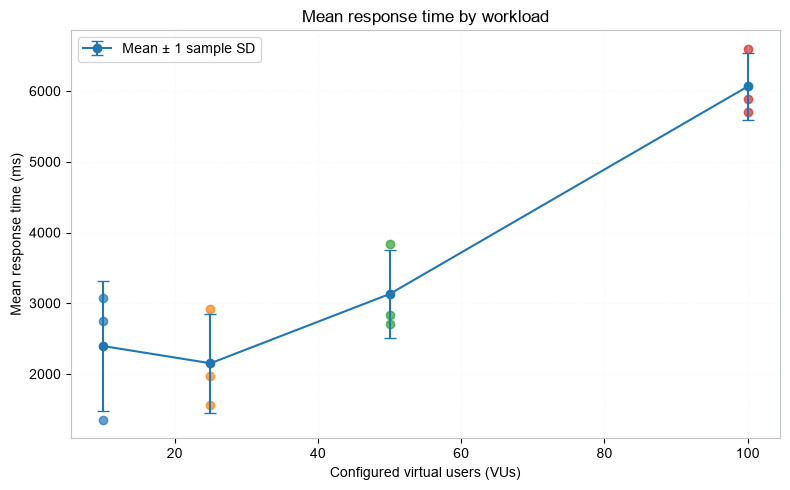

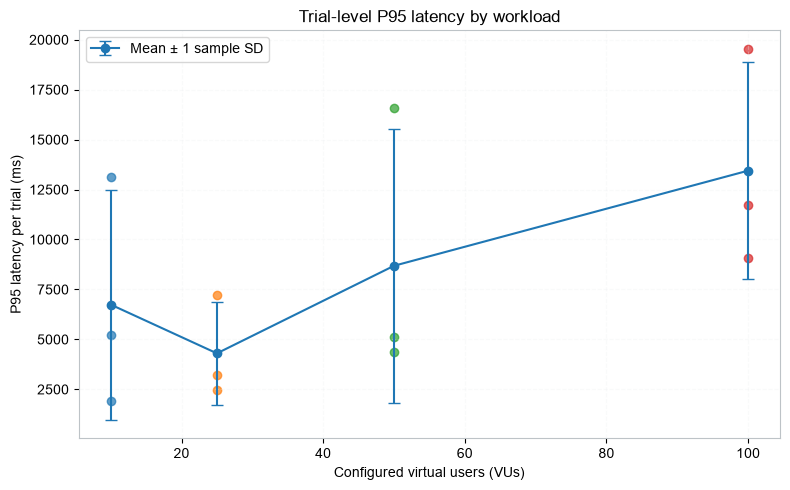

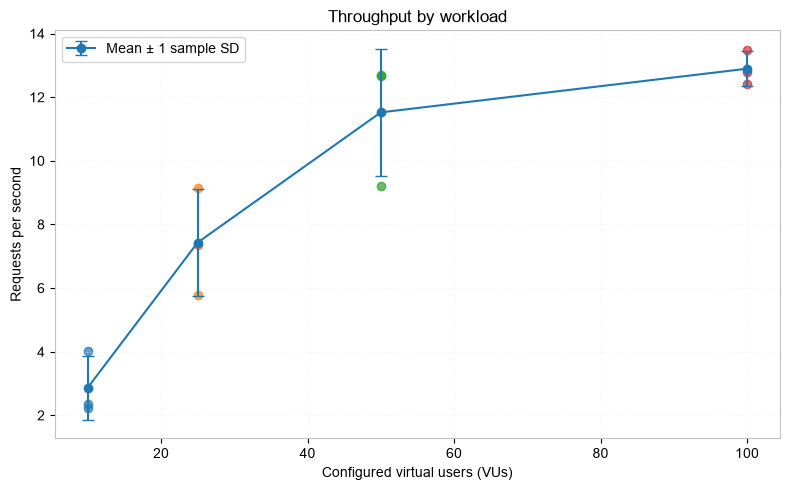

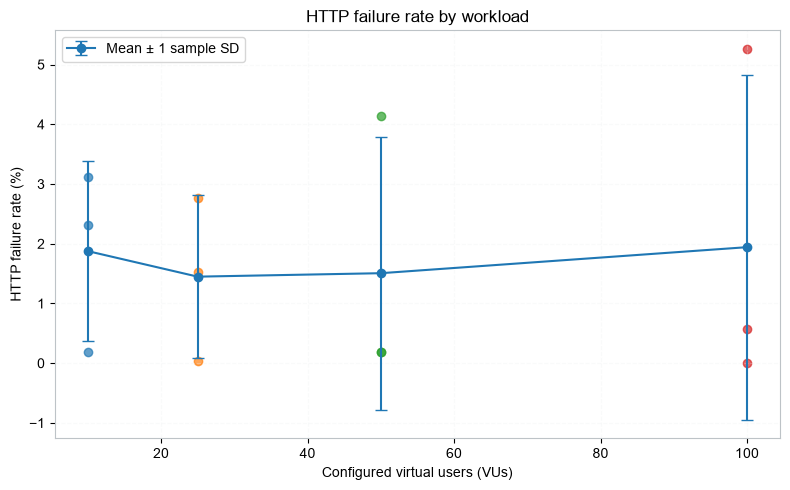

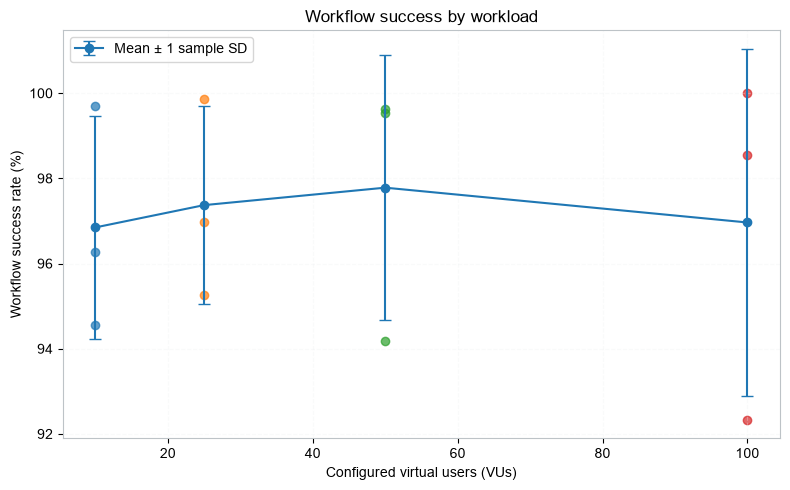

In [42]:
plot_specs = [
    ("Avg_Latency_ms", "Mean response time (ms)", "Mean response time by workload", "mean_response_time.png"),
    ("P95_ms", "P95 latency per trial (ms)", "Trial-level P95 latency by workload", "p95_response_time.png"),
    ("RPS", "Requests per second", "Throughput by workload", "throughput.png"),
    ("HTTP_Failed_Rate_pct", "HTTP failure rate (%)", "HTTP failure rate by workload", "http_failure_rate.png"),
    ("Workflow_Success_Rate_pct", "Workflow success rate (%)", "Workflow success by workload", "workflow_success_rate.png")
]
for col, ylabel, title, filename in plot_specs:
    if col not in trials.columns:
        print(f"Skipping {filename}: missing column {col}")
        continue
    valid = trials[["VUs", col]].dropna()
    if valid.empty:
        print(f"Skipping {filename}: no valid observations")
        continue
    grouped = valid.groupby("VUs")[col]
    means, sds = grouped.mean(), grouped.std()
    fig, ax = plt.subplots(figsize=(8, 5))
    ax.errorbar(means.index, means.values, yerr=sds.fillna(0).values, marker="o", capsize=4, label="Mean ± 1 sample SD")
    for vu, group in valid.groupby("VUs"):
        ax.scatter([vu] * len(group), group[col], alpha=0.7, label=None)
    ax.set_title(title)
    ax.set_xlabel("Configured virtual users (VUs)")
    ax.set_ylabel(ylabel)
    ax.grid(True, alpha=0.3)
    ax.legend()
    fig.tight_layout()
    fig.savefig(OUT_DIR / filename, dpi=200, bbox_inches="tight")
    plt.show()
    plt.close(fig)

### Cross-check the supplied Chapter 4 summary

Recalculates means from `all_trials.csv` and compares them with matching mean columns in `chapter4_summary.csv`. Differences are displayed for review; this does not overwrite the supplied summary.

In [43]:
# Accept both the unit-explicit names and the shorter names used in some exports.
pairs = {
    "Avg_Latency_ms": ["Avg_Latency_ms_Mean", "Avg_Latency_Mean"],
    "P50_ms": ["P50_ms_Mean", "P50_Mean"],
    "P90_ms": ["P90_ms_Mean", "P90_Mean"],
    "P95_ms": ["P95_ms_Mean", "P95_Mean"],
    "P99_ms": ["P99_ms_Mean", "P99_Mean"],
    "Max_Latency_ms": ["Max_Latency_ms_Mean", "Max_Latency_Mean"],
    "RPS": ["RPS_Mean"],
    "HTTP_Failed_Rate_pct": ["HTTP_Failed_Rate_pct_Mean", "HTTP_Failed_Rate_Mean"],
    "HTTP_Success_Rate_pct": ["HTTP_Success_Rate_pct_Mean", "HTTP_Success_Rate_Mean"],
    "Workflow_Success_Rate_pct": ["Workflow_Success_Rate_pct_Mean", "Workflow_Success_Mean"]
}
checks = []
if "VUs" not in existing_summary.columns:
    print("Cross-check skipped: chapter4_summary.csv has no VUs column.")
else:
    for trial_col, summary_candidates in pairs.items():
        summary_col = next((name for name in summary_candidates if name in existing_summary.columns), None)
        if trial_col not in trials.columns or summary_col is None:
            continue
        calc = trials.groupby("VUs")[trial_col].mean().rename("Recalculated_Mean")
        supplied = existing_summary.groupby("VUs")[summary_col].mean().rename("Supplied_Summary_Mean")
        comp = pd.concat([calc, supplied], axis=1).reset_index()
        comp["Metric"] = trial_col
        comp["Summary_Column"] = summary_col
        comp["Difference"] = comp["Recalculated_Mean"] - comp["Supplied_Summary_Mean"]
        checks.append(comp)
    if checks:
        crosscheck = pd.concat(checks, ignore_index=True)
        display(crosscheck[["Metric", "Summary_Column", "VUs", "Recalculated_Mean", "Supplied_Summary_Mean", "Difference"]].round(6))
        crosscheck.to_csv(OUT_DIR / "summary_cross_check.csv", index=False)
    else:
        print("No matching metric/summary column pairs were found.")

,Metric,Summary_Column,VUs,Recalculated_Mean,Supplied_Summary_Mean,Difference
0,Avg_Latency_ms,Avg_Latency_ms_Mean,10.0,2395.137909,2395.138,-0.000091
1,Avg_Latency_ms,Avg_Latency_ms_Mean,25.0,2151.509548,2151.510,-0.000452
2,Avg_Latency_ms,Avg_Latency_ms_Mean,50.0,3130.008848,3130.009,-0.000152
3,Avg_Latency_ms,Avg_Latency_ms_Mean,100.0,6064.828815,6064.829,-0.000185
4,P50_ms,P50_ms_Mean,10.0,1497.311333,1497.311,0.000333
5,P50_ms,P50_ms_Mean,25.0,1510.983833,1510.984,-0.000167
6,P50_ms,P50_ms_Mean,50.0,2403.959500,2403.960,-0.000500
7,P50_ms,P50_ms_Mean,100.0,5319.611167,5319.611,0.000167
8,P90_ms,P90_ms_Mean,10.0,3061.612467,3061.612,0.000467
9,P90_ms,P90_ms_Mean,25.0,2790.425000,2790.425,-0.000000


### Export a concise analysis inventory

Lists the files generated in `analysis_outputs/`. Use the audit tables alongside the figures when deciding which results are suitable for the thesis.

In [44]:
outputs = sorted(p.name for p in OUT_DIR.iterdir() if p.is_file())
display(pd.DataFrame({"Generated output": outputs}))

,Generated output
0,http_count_rate_validation.csv
1,http_failure_rate.png
2,independent_descriptive_summary.csv
3,mean_response_time.png
4,p95_response_time.png
5,quality_flags.csv
6,summary_cross_check.csv
7,throughput.png
8,trial_audit.csv
9,workflow_success_rate.png


## Reporting and interpretation cautions

- Report means and sample SD across the available trial-level observations at each workload; show the number of observations (`*_n`) because missing data can change the denominator.
- Refer to `P95_ms_Mean` and `P99_ms_Mean` as **means of trial-level percentiles**, not pooled request percentiles.
- The supplied records previously showed maximum latency close to 30 seconds in many trials. Treat this as a possible timeout signal only after checking raw K6 JSON and error details.
- If HTTP counts align with the opposite percentage labels, document this as an unresolved export/label inconsistency; do not silently swap columns in the analysis notebook.
- Missing workflow counters and differences between `Iterations` and `Workflow_Completed` require checking the metric definitions and raw records.
- CPU/memory observed on the load generator are not server-side Deno Deploy or Supabase resource measurements.
- Login occurs in K6 `setup()` once per execution (per the stated test design), so HTTP request throughput may include setup traffic depending on how the CSV was extracted. Confirm the metric definition before describing RPS.
- Conclusions apply only to the tested deployment, representative authenticated three-GET workflow, configured workloads, and test duration. These data alone do not establish maximum capacity, general performance of every module, or internal autoscaling behavior.
- Before judging requirement compliance, compare results with the exact approved non-functional requirement thresholds and traceability IDs; do not invent thresholds or requirement IDs.